In [67]:
import numpy as np, matplotlib.pyplot as plt, pandas as pd, xarray as xr, scipy.stats as stats, json, scipy.optimize as op, pathlib, os, seaborn as sns, warnings
# plt.style.use('dark_background')
warnings.filterwarnings("ignore")

In [68]:
class gb_experiments:
    def __init__(self, df):
        expnum = df['expnum']
        self.input = df
        self.name = f'gb_5_{expnum}'
        self.date = df['date']
        
        self.rho = 995
        self.g = 9.81
        self.flow_width = 0.065 # m
        self.grain_diameter = 0.0049 # m
        self.rhos = 2558 # kg/m3
        self.LDA_x_loc = 2.2 # m
        
        if df['discharge']:
            self.discharge_height = df['discharge_height']
            self.discharge_time = df['discharge_time']
            self.discharge = self.discharge_calc()
        else: 
            self.discharge = np.nan
        
        self.feed_flux = (df['feeder_mass'] / df['feeder_times']).mean()
        self.vol_flux_per_width_feed = self.feed_flux / self.rhos / self.flow_width
        self.q8_feed = self.vol_flux_per_width_feed / np.sqrt(self.g * (self.rhos/self.rho - 1) * self.grain_diameter**3)
        
        self.ind_start = 1
        self.ind_end = 5
        try: 
            self.water_elev = df['water_elev']
            self.bed_elev = df['bed_elev']
            self.slope_calc()
        except:
            self.water_slope = np.nan
            self.bed_slope = np.nan
            self.tau8 = np.nan
            self.shear_stress = np.nan
        
        try:
            self.mass_flux_masses = df['mass_flux_mass'][df['mass_flux_range'][0]:df['mass_flux_range'][1]]
            self.mass_flux_times = df['mass_flux_times'][df['mass_flux_range'][0]:df['mass_flux_range'][1]]
            
            self.mass_flux = (self.mass_flux_masses / self.mass_flux_times).mean()
            self.mass_flux_last = np.mean((self.mass_flux_masses / self.mass_flux_times)[-3:-1])
            
            self.vol_flux_per_width = self.mass_flux / self.rhos / self.flow_width
            self.q8 = self.vol_flux_per_width / np.sqrt(self.g * (self.rhos/self.rho - 1) * self.grain_diameter**3)
        except:
            self.mass_flux = np.nan
            self.mass_flux_last = np.nan
            self.q8 = np.nan
        
        self.df = pd.DataFrame({'name': self.name, 'date': self.date, 'discharge': self.discharge, 'water_slope': self.water_slope, 'bed_slope': self.bed_slope, 'flow_depth': self.flow_depth, 'mass_flux': self.mass_flux, 'feed_flux': self.feed_flux, 'shear_stress': self.shear_stress, 'reynolds_stress': np.nan, 'tau8': self.tau8, 'q8': self.q8, 'q8_feed': self.q8_feed}, index=[0])
            
            
    def discharge_calc(self):
        # Bucket calibration is used to measure water flux from flume
        h = np.array([np.array([17.9,  17.8, 17.8, 17.85]).mean(),
                    np.array([17.7,  17.6, 17.8, 17.6]).mean(),
                    np.array([19.75, 19.8, 19.8, 19.8]).mean(),
                    np.array([19.9,  19.9, 19.9, 19.85]).mean(),
                    np.array([21.0,  21.1, 21.0, 21.0]).mean(),
                    np.array([21.8,  21.9, 21.8, 21.8]).mean()]).astype(float) # cm
        vol = np.array([10.0, 10.0, 11.25, 11.25, 12.0, 12.5]) # L
        plt.plot(h, vol, 'ko')

        def depth_vol(x, m, b):
            return m*x + b

        (bucket_m, bucket_b), non = op.curve_fit(depth_vol, h, vol)
        # x = np.linspace(15, 25, 100)
        # plt.plot(x, depth_vol(x, bucket_m, bucket_b), 'r')

        def discharge_func(h, t):
            if np.isnan(h).any():
                return np.nan

            elif np.isnan(t).any():
                    return np.nan
            else:
                return depth_vol(h*100, bucket_m, bucket_b) / t
            
        return discharge_func(self.discharge_height, self.discharge_time)
                
                
    def slope_calc(self):
        self.distance_from_upstream_end = np.array([100, 150, 200, 250, 300, 350]) / 100 # m
        self.thickness_of_pink_foam = np.array([5.1, 5.1, 5.1, 5.2, 5.2, 5.2]) / 100 # m
        self.elevation_above_flume_deck = np.array([22.4, 23.3, 24.2, 25.0, 25.8, 26.7]) / 100 # m

        slope, intercept, r_value, p_value, std_err = stats.linregress(self.distance_from_upstream_end, self.elevation_above_flume_deck)
        self.flume_bed_slope = np.degrees(np.arctan(slope))
    
        self.flow_depth = np.mean(self.water_elev[self.ind_start:self.ind_end] - self.bed_elev[self.ind_start:self.ind_end]) # m
        bed_surface = self.thickness_of_pink_foam[self.ind_start:self.ind_end] - self.elevation_above_flume_deck[self.ind_start:self.ind_end] + self.bed_elev[self.ind_start:self.ind_end]
        slope, intercept, r_value, p_value, std_err = stats.linregress(self.distance_from_upstream_end[self.ind_start:self.ind_end], bed_surface)
        self.bed_slope = -np.degrees(np.arctan(slope))

        water_surface = self.thickness_of_pink_foam[self.ind_start:self.ind_end] - self.elevation_above_flume_deck[self.ind_start:self.ind_end] + self.water_elev[self.ind_start:self.ind_end]
        print(water_surface)
        slope, intercept, r_value, p_value, std_err = stats.linregress(self.distance_from_upstream_end[self.ind_start:self.ind_end], water_surface)
        self.water_slope = -np.degrees(np.arctan(slope))
        
        self.hydrad = self.flow_depth * self.flow_width / (2 * self.flow_depth + self.flow_width) # m
        self.shear_stress = self.rho * self.g * self.hydrad * np.tan(np.radians(self.water_slope))
        self.tau8 = self.shear_stress / self.rho / self.g / (self.rhos/self.rho - 1) / self.grain_diameter
        
        func = lambda x, m, b: m*x + b
        (bed_m, bed_b), non = op.curve_fit(func, self.distance_from_upstream_end, self.elevation_above_flume_deck.max() - self.elevation_above_flume_deck + self.thickness_of_pink_foam + self.bed_elev)
        self.bed_elev_loc_LDA = func(self.LDA_x_loc, bed_m, bed_b)
        (foam_m, foam_b), non = op.curve_fit(func, self.distance_from_upstream_end, self.elevation_above_flume_deck.max() - self.elevation_above_flume_deck + self.thickness_of_pink_foam)
        self.foam_base_loc_LDA = func(self.LDA_x_loc, foam_m, foam_b)
        self.bed_ref_LDA = self.bed_elev_loc_LDA - self.foam_base_loc_LDA
        

    def plot_bed_slope(self):
        plt.figure(figsize=(8, 1.5))
        x = self.distance_from_upstream_end.max() - self.distance_from_upstream_end
        flume = self.elevation_above_flume_deck.max() - self.elevation_above_flume_deck
        foam = flume + self.thickness_of_pink_foam
        bed = flume + self.thickness_of_pink_foam + self.bed_elev
        water = flume + self.thickness_of_pink_foam + self.water_elev
        plt.plot(x, flume, 'k')
        plt.plot(x, foam, 'm')
        plt.plot(x, bed, 'ro--')
        plt.plot(x, water, 'bo--')
        x_plot = np.linspace(x[self.ind_start], x[self.ind_end-1], 100)
        y = np.tan(np.radians(self.bed_slope)) * (x_plot - x[3]) + bed[3]
        plt.plot(x_plot, y, 'r-')
        
        y = np.tan(np.radians(self.water_slope)) * (x_plot - x[3]) + water[3]
        plt.plot(x_plot, y, 'b-')
        
        plt.plot(self.distance_from_upstream_end.max() - self.LDA_x_loc, self.bed_elev_loc_LDA, 'ko')
        plt.plot(self.distance_from_upstream_end.max() - self.LDA_x_loc, self.foam_base_loc_LDA, 'ko')
        

        plt.xlim(0, 2.5)
        plt.ylim(0, 0.3)
        sns.despine()


    def plot_mass_flux(self):
        plt.figure(figsize=(8, 1.5))
        n = len(self.mass_flux_times)
        plt.plot(self.input['t_step'] * np.arange(n), self.mass_flux_masses/self.mass_flux_times * 1000, 'ro')
        plt.plot(self.input['t_step'] * np.arange(n), self.feed_flux.mean() * 1000 * np.ones(n), 'b--')
        plt.xlim(0, np.ceil(self.input['t_step'] * n))
        plt.ylim(0, np.ceil(1.1*self.feed_flux.mean() * 1000))
        sns.despine()
        
        
gb5 = [[], [], [], []]

### gb_5_01

[-0.071 -0.078 -0.087 -0.099]


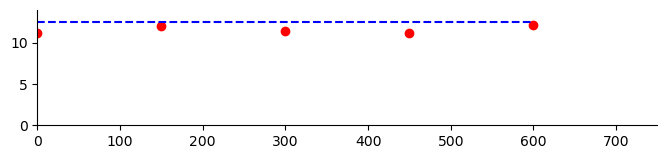

In [69]:
gb_5_01 = {
        'expnum': 1,
        'date': '2_12_2023',
        # feeder measurements
        'feeder_one_height': 55, # permille
        'feeder_two_height': 55, # permille
        'feeder_times': np.array([30, 30]), # s
        'feeder_mass': np.array([377.92, 370.97]) / 1000, # kg

        # discharge measurements
        'discharge': None,
        'pump_freq': 32.0, # Hz

        # Bed slope measurements - done at the very end, after tray 12
        'bed_elev': np.array([6.2, 5.7, 5.8, 5.5, 5.5, 5.2]) / 100, # m
        'water_elev': np.array([12.0, 11.1, 11.3, 11.1, 10.7, 10.9]) / 100, # m

        # mass flux measurements
        'mass_flux_range': np.array([1, 6]),
        'mass_flux_times': np.array([30, 30, 30, 30, 30, 30, 30]), # s
        'mass_flux_mass': np.array([328.47, 335.43, 362.15, 342.51, 334.72, 363.83, 342.48]) / 1000, # kg
        't_step': 150, # s
        }

gb5[0] = gb_experiments(gb_5_01)
gb5[0].plot_mass_flux()

### gb_5_02

[-0.082 -0.091 -0.096 -0.106]


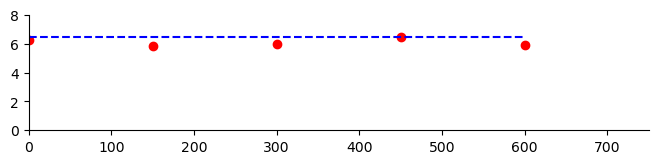

In [70]:
gb_5_02 = {
        'expnum': 2,
        'date': '2_12_2023',
        # feeder measurements
        'feeder_one_height': 20, # permille
        'feeder_two_height': 20, # permille
        'feeder_times': np.array([30, 30, 30]), # s
        'feeder_mass': np.array([193.1, 192.4, 197.35]) / 1000, # kg

        # discharge measurements
        'discharge': None,
        'pump_freq': 32.0, # Hz

        # Bed slope measurements - done at the very end, after tray 12
        'bed_elev': np.array([5.1, 4.8, 4.8, 4.9, 4.9, 4.9]) / 100, # m
        'water_elev': np.array([10.5, 10.0, 10.0, 10.2, 10.0, 10.3]) / 100, # m

        # mass flux measurements
        'mass_flux_range': np.array([1, 6]),
        'mass_flux_times': np.array([30, 30, 30, 30, 30, 30, 30]), # s
        'mass_flux_mass': np.array([176.24, 186.70, 175.29, 179.70, 193.34, 178.21, 176.68]) / 1000, # kg
        't_step': 150, # s
        }

gb5[1] = gb_experiments(gb_5_02)
gb5[1].plot_mass_flux()

### gb_5_03

[-0.091  -0.098  -0.1005 -0.112 ]


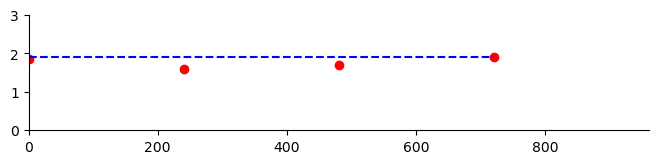

In [71]:
gb_5_03 = {
        'expnum': 3,
        'date': '3_12_2023',
        # feeder measurements
        'feeder_one_height': -15, # permille
        'feeder_two_height': -15, # permille
        'feeder_times': np.array([60, 60, 60]), # s
        'feeder_mass': np.array([113.5, 110.8, 117.4]) / 1000, # kg

        # discharge measurements
        'discharge': None,
        'pump_freq': 32.0, # Hz

        # Bed slope measurements - done at the very end, after tray 12
        'bed_elev': np.array([3.6, 3.5, 3.7, 4.1, 4.3, 4.1]) / 100, # m
        'water_elev': np.array([9.4, 9.1, 9.3, 9.75, 9.4, 9.9]) / 100, # m

        # mass flux measurements
        'mass_flux_range': np.array([1, 5]),
        'mass_flux_times': np.array([60, 60, 60, 60, 60, 60]), # s
        'mass_flux_mass': np.array([103.84, 110.32, 95.82, 101.27, 114.78, 127.71]) / 1000, # kg
        't_step': 240, # s
        }

gb5[2] = gb_experiments(gb_5_03)
gb5[2].plot_mass_flux()

[-0.04  -0.053 -0.071 -0.09 ]


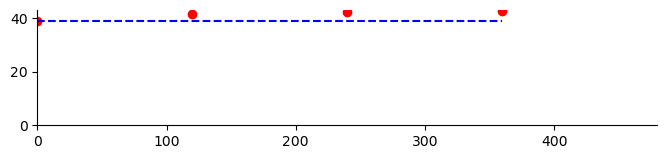

In [72]:
gb_5_04 = {
        'expnum': 4,
        'date': '3_12_2023',
        # feeder measurements
        'feeder_one_height': 140, # permille
        'feeder_two_height': 140, # permille
        'feeder_times': np.array([30, 30]), # s
        'feeder_mass': np.array([1167.1, 1155.6]) / 1000, # kg

        # discharge measurements
        'discharge': None,
        'pump_freq': 32.0, # Hz

        # Bed slope measurements - done at the very end, after tray 12
        'bed_elev': np.array([11.6, 10.4, 9.5, 8.5, 7.4, 6.7]) / 100, # m
        'water_elev': np.array([16.0, 14.2, 13.8, 12.7, 11.6, 11.2]) / 100, # m

        # mass flux measurements
        'mass_flux_range': np.array([0, 4]),
        'mass_flux_times': np.array([15, 15, 15, 15, 15]), # s
        'mass_flux_mass': np.array([580.93, 620.29, 631.85, 636.49, 659.55]) / 1000, # kg
        't_step': 120, # s
        }

gb5[3] = gb_experiments(gb_5_04)
gb5[3].plot_mass_flux()

### Processing data

In [73]:
gb_5s = pd.concat([gb5[i].df for i in [0, 1, 2, 3]])
# dequil_mass_flux = np.nanstd(np.array(dict1['mass_flux_mass'][m1:m2])/(np.array(dict1['mass_flux_times'][m1:m2])*1000))/np.sqrt(np.array(dict1['mass_flux_mass'][m1:m2]).size)
gb_5s.to_csv('gb_5_data.csv', index=False)
gb_5s

,name,date,discharge,water_slope,bed_slope,flow_depth,mass_flux,feed_flux,shear_stress,reynolds_stress,tau8,q8,q8_feed
0,gb_5_1,2_12_2023,NaN,1.065579,1.008302,0.054250,0.011591,0.012481,3.689934,NaN,0.049113,0.051774,0.055751
0,gb_5_2,2_12_2023,NaN,0.882285,0.859372,0.052000,0.006088,0.006476,3.006373,NaN,0.040015,0.027195,0.028927
0,gb_5_3,3_12_2023,NaN,0.750532,0.584397,0.054875,0.001759,0.001898,2.609961,NaN,0.034738,0.007858,0.008479
0,gb_5_4,3_12_2023,NaN,1.924414,2.050313,0.041250,0.041159,0.038712,5.961790,NaN,0.079351,0.183848,0.172914


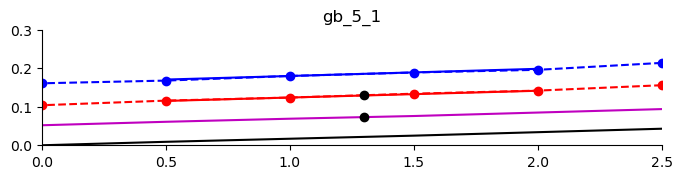

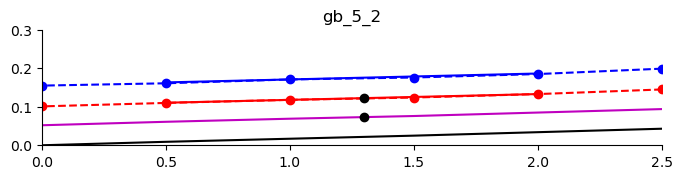

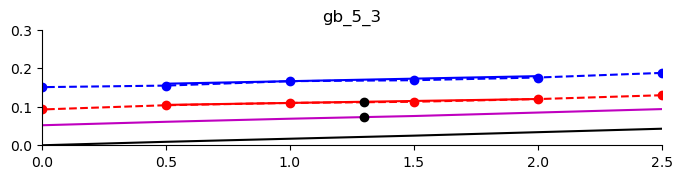

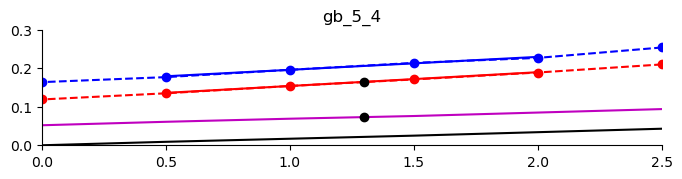

In [74]:
for gb in gb5:
    gb.plot_bed_slope()
    plt.title(gb.name)

### Feeder Calibration

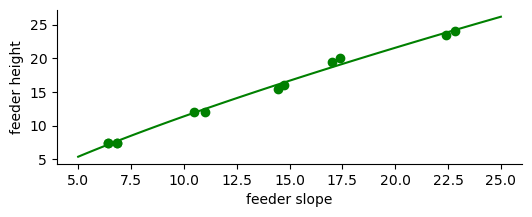

In [75]:
plt.figure(figsize=(6, 2))
df_feeder = pd.read_csv('feeder_calib.tsv', sep='\t')

feeder_calib = lambda x, m, b, c: m*x**c + b

(m1, b1, c1), non = op.curve_fit(feeder_calib, df_feeder.slope_deg, df_feeder.ruler_height_cm)
feeder_calib_height = lambda x: feeder_calib(x, m1, b1, c1)
feeder_calib_height_inv = lambda x: ((x - b1) / m1)**(1/c1)

x = np.linspace(5, 25, 100)

plt.plot(df_feeder.slope_deg, df_feeder.ruler_height_cm, 'go')
plt.plot(x, feeder_calib_height(x), 'g')


plt.xlabel('feeder slope')
plt.ylabel('feeder height')
sns.despine()

In [76]:
dfc = pd.read_csv('gb_feeder_calib.csv')
# plt.plot( dfc.grain_flux, dfc.pipe_grade, 'o')

feeder_calib = lambda x, m, b, c: m*x**c + b

(m1, b1, c1), non = op.curve_fit(feeder_calib, dfc.grain_flux, dfc.pipe_grade)
feeder_calib_slope = lambda x: feeder_calib(x, m1, b1, c1)

# x = np.linspace(0, 40, 100)

# plt.plot(dfc.grain_flux, dfc.pipe_grade, 'go')
# plt.plot(x, feeder_calib_slope(x), 'g')

proposed_experiments = np.array([0.002, 0.00625, 0.0125, 0.04]) * 1000

# plt.plot(proposed_experiments, feeder_calib_slope(proposed_experiments), 'ro')

pipe_grade_per_mille = feeder_calib_slope(proposed_experiments/2)
pipe_grade_degrees = np.degrees(np.arctan(feeder_calib_slope(proposed_experiments/2) / 1000))
back_height_cm = feeder_calib_height(np.degrees(np.arctan(feeder_calib_slope(proposed_experiments/2) / 1000)))
for i in range(len(proposed_experiments)): print(f'For a flux of {proposed_experiments[i]} grams/second use two feeders with a pipe slope of {pipe_grade_per_mille[i]} permille.')

For a flux of 2.0 grams/second use two feeders with a pipe slope of -14.44022472561786 permille.
For a flux of 6.25 grams/second use two feeders with a pipe slope of 20.240424333028173 permille.
For a flux of 12.5 grams/second use two feeders with a pipe slope of 55.32154173776054 permille.
For a flux of 40.0 grams/second use two feeders with a pipe slope of 156.11573043251224 permille.


### Experiment results

In [77]:
for i in range(len(gb5)):
    # plt.figure(i)
    vdata = np.array(list(pathlib.Path(f'/Users/ericdeal/Documents/1_eth/1_projects/grain_shape/2023_experiments/gb_exps/velocity_data/Narrow_Flume_Gb_5_0{i+1}').glob('*_Coincident*.csv')))
    vdata = vdata[np.argsort([int(name.stem.split('Gb')[1].split('_')[3][1]) for name in vdata])]

    reynolds_stress = np.zeros(len(vdata))
    mean_vel = np.zeros(len(vdata))
    heights = np.zeros(len(vdata))
    for j in range(len(vdata)):
        df = pd.read_csv(vdata[j], header=1)

        u = df[' \"Velocity Ch. 1 (m/sec)\"'].values
        v = df[' \"Velocity Ch. 2 (m/sec)\"'].values
        mean_vel[j] = np.sqrt((u.mean()**2 + v.mean())**2)
        reynolds_stress[j] = np.mean((u - u.mean()) * (v - v.mean()))
        
        heights[j] = float(df[' \"Y Axis Position\"'].values[0]) - gb5[i].bed_ref_LDA*1000
                
    reynolds_stress = reynolds_stress[np.argsort(heights)][::-1]
    mean_vel = mean_vel[np.argsort(heights)][::-1]
    heights = heights[np.argsort(heights)][::-1]
    lower_depth_threshold = 0
    reynolds_stress = reynolds_stress[heights >= lower_depth_threshold]
    mean_vel = mean_vel[heights >= lower_depth_threshold]
    heights = heights[heights >= lower_depth_threshold]
    
    pd.DataFrame({'y': heights, 'reynolds_stress': reynolds_stress, 'mean_vel': mean_vel}).to_csv(f'velocity_data/gb_5_{i+1}_LDA_data_processed.csv', index=False)